# Wavebit Tutorial 8
 FDTD, the time-domain path

Wavebit solves a periodic structure two ways. RCWA (`wavebit.rcwa`, tutorials 1-7)
expands the field in diffraction orders and solves one frequency at a time. FDTD
(`wavebit.fdtd`) steps Maxwell's equations through time on a Yee grid.

Reach for FDTD when you want **a whole band from one run**, **a material with a Drude or
Lorentz pole**, or **the field itself** rather than order amplitudes. Reach for RCWA when the
scene is a stack of uniform or gratinged layers at one wavelength: it is far faster there, and
it is the reference this page checks against.

This path is **research alpha**. It is validated on the scenes in
[`../docs/fdtd-alpha.md`](../docs/fdtd-alpha.md) and no further; the last section says where
the edges are.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import wavebit

## 8.1 The same slab, both solvers

A 0.4 um film of relative permittivity 2.25 in vacuum, at normal incidence, 0.9 um light.
`tetm='te'` declares that this problem has no polarization degree of freedom, which buys the
fast 1D path in both solvers.

Lengths share one unit. Micrometres here, but only the ratios matter.

In [2]:
slab = dict(structure=np.full((1, 1, 1), 2.25),   # relative permittivity, Z Y X
            thickness=[.4], top=1., bot=1., period=[.5],
            wavelength=.9, tetm='te')

exact = wavebit.rcwa(backend=0, truncation_order=[0], **slab).solve()
stepped = wavebit.fdtd(**slab, resolution=30., n_periods=60)

print(f'RCWA   R {np.sum(exact.R):.4f}   T {np.sum(exact.T):.4f}')
print(f'FDTD   R {np.sum(stepped.R):.4f}   T {np.sum(stepped.T):.4f}')

RCWA   R 0.1152   T 0.8848
FDTD   R 0.1128   T 0.8869


`resolution` is cells per unit length, so 30 puts 12 cells across this film.
`n_periods` is how many optical cycles to run. Both decide how right the answer is, and both
are checked below rather than trusted.

## 8.2 Did the run finish?

A time-domain answer is only as good as its settling: stop too early and the field is still
ringing through the monitors. `return_diagnostics=True` hands back the run's own report.
`residual` is the field's tail-to-peak ratio, so small means the pulse has left.

In [3]:
result, diagnostics = wavebit.fdtd(**slab, resolution=30., n_periods=60,
                                   return_diagnostics=True)

print('residual       ', f"{diagnostics['residual']:.2e}")
print('time step dt   ', f"{float(diagnostics['dt']):.4f}")
print('steps          ', diagnostics['n_steps'])
print('grid (nz,ny,nx)', diagnostics['grid'].nz, diagnostics['grid'].ny, diagnostics['grid'].nx)

residual        1.50e-05
time step dt    0.0233
steps           2315
grid (nz,ny,nx) 73 1 15


## 8.3 Refinement is the check that matters

One number proves nothing. Halve the cell and the error against RCWA should fall with it.

In [4]:
reference = np.sum(exact.T)
for resolution in (20., 40., 80.):
    run = wavebit.fdtd(**slab, resolution=resolution, n_periods=60)
    print(f'resolution {resolution:5.0f}   T {np.sum(run.T):.5f}   '
          f'error {abs(np.sum(run.T) - reference):.5f}')

resolution    20   T 0.88871   error 0.00391


resolution    40   T 0.88678   error 0.00198


resolution    80   T 0.88529   error 0.00050


## 8.4 A band from one run

Give `wavelength` a list and one pulse carries the whole band, for what one wavelength costs.
This is what the time-domain path is for. RCWA solves each wavelength separately.

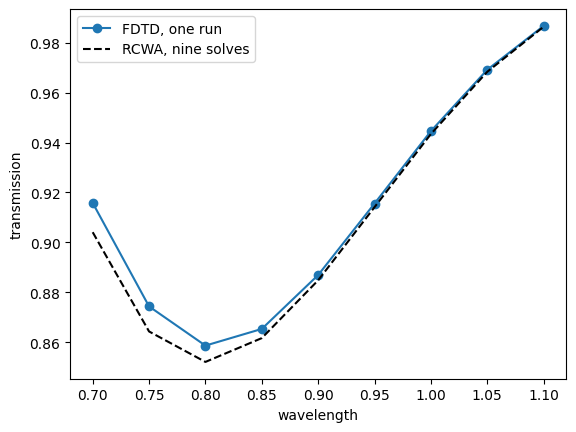

In [5]:
band = np.linspace(.7, 1.1, 9)
spectrum = wavebit.fdtd(**dict(slab, wavelength=list(band)), resolution=30., n_periods=80)
transmission = [float(np.sum(r.T)) for r in spectrum]

per_wavelength = [float(np.sum(wavebit.rcwa(backend=0, truncation_order=[0],
                                            **dict(slab, wavelength=float(w))).solve().T))
                  for w in band]

plt.plot(band, transmission, 'o-', label='FDTD, one run')
plt.plot(band, per_wavelength, 'k--', label='RCWA, nine solves')
plt.xlabel('wavelength')
plt.ylabel('transmission')
plt.legend()
plt.show()

## 8.5 A grating, order by order

A binary grating splits the light. Both solvers report per-order efficiencies, and the orders
are labelled: match them by label, never by array position. RCWA keeps every order up to its
truncation; FDTD keeps the ones that propagate.

In [6]:
grating = dict(structure=np.where(np.arange(8) < 4, 2.25, 1.)[None, None, :],
               thickness=[.3], top=1., bot=1., period=[.8],
               wavelength=.9, tetm='te', theta=np.deg2rad(10.))

grating_exact = wavebit.rcwa(backend=0, truncation_order=[12], **grating).solve()
grating_stepped = wavebit.fdtd(**grating, resolution=40., n_periods=80)

labels = list(np.asarray(grating_exact.orders_u).ravel())
for position, order in enumerate(np.asarray(grating_stepped.orders_u).ravel()):
    rcwa_t = float(np.asarray(grating_exact.T).ravel()[labels.index(order)])
    fdtd_t = float(np.asarray(grating_stepped.T).ravel()[position])
    print(f'order {order:+d}   RCWA {rcwa_t:.4f}   FDTD {fdtd_t:.4f}')

order -1   RCWA 0.0592   FDTD 0.0594
order +0   RCWA 0.9164   FDTD 0.9164
order +1   RCWA 0.0000   FDTD 0.0000


## 8.6 Two engines behind one function

`wavebit.fdtd` is one door to two time-domain engines. Both step Maxwell's equations on a Yee
grid, but they are separate implementations and do not offer the same things. Sections 8.1-8.5
use one and sections 8.7-8.8 the other, and every call on this page is written out in full: to
use a column below, start from a call in the sections it names.

| | sections 8.1-8.5 | sections 8.7-8.8 |
| --- | --- | --- |
| incident wave | imposed through an auxiliary one-dimensional grid | current sheets, calibrated against a uniform-medium run |
| array library | NumPy | NumPy, JAX or Torch |
| derivatives | none | on JAX and Torch; NumPy carries no gradients |
| light from | above | above or below |
| structure | a raster | a raster, or the shape recipes of 8.8 |
| `resolution` | optional: 20 cells per wavelength in the densest material if left out | required |
| settling report | `residual`, on every run | `convergence_window=`, when asked for |
| cost on the same grid | the faster | much slower |

Driven onto the same grid on 40 scenes, the two made the same error on most of the comparisons
that could be resolved, and no scene ranked either one as the more accurate.
[`../docs/fdtd-route-parity.md`](../docs/fdtd-route-parity.md) records where they disagreed and
what that comparison did not cover.

## 8.7 A derivative of a time-domain solve

With JAX or Torch as the array library, the whole time loop of the second engine in 8.6 is
differentiable. Here is the transmission's derivative with respect to the film's permittivity,
beside a finite difference of the same function -- the control that says the derivative belongs
to the thing it claims.

`resolution=20.` keeps the three solves quick, and it is coarse: the `T` printed below sits about
0.006 above RCWA's in 8.1. The finite difference runs on the same mesh, so the agreement checks
the derivative of this discretised model, not whether 20 cells are enough.

In [7]:
import jax

wavebit.enable_x64()   # 64-bit, or the difference below is noise


def transmission_of(epsilon):
    run = wavebit.fdtd(structure=epsilon*np.ones((1, 1, 1)), thickness=[.4], top=1., bot=1.,
                       period=[.5], wavelength=.9, tetm='te', backend='jax',
                       resolution=20., n_periods=40)
    return run.T.sum()


value, derivative = jax.value_and_grad(transmission_of)(jax.numpy.asarray(2.25))
step = .0005
difference = (float(transmission_of(jax.numpy.asarray(2.25 + step)))
              - float(transmission_of(jax.numpy.asarray(2.25 - step))))/(2*step)

print(f'T                  {float(value):.6f}')
print(f'dT/d(epsilon)      {float(derivative):.6f}')
print(f'finite difference  {difference:.6f}')

T                  0.890693
dT/d(epsilon)      -0.206426
finite difference  -0.206426


## 8.8 Shapes instead of a raster

The engine of 8.7 also takes a **shape recipe**: a rectangle, circle or ellipse placed in a
layer by its centre and size. The solver integrates the shape into the cells rather than
drawing it on a raster first, so the geometry is exact and its position and size stay
differentiable.

In [8]:
patch = dict(structure=[dict(background=1., shapes=[
                 dict(type='rectangle', lx=.25, ly=.25, cx=0., cy=0., material=2.25)])],
             thickness=[.3], top=1., bot=1., period=[.5, .5],
             wavelength=.9, theta=0., psi=0.)

square_exact = wavebit.rcwa(backend=0, truncation_order=[5, 5], **patch).solve()
square = wavebit.fdtd(**patch, backend=0, resolution=16., n_periods=40)

print(f'RCWA   R {np.sum(square_exact.s_inc.R):.5f}   T {np.sum(square_exact.s_inc.T):.5f}')
print(f'FDTD   R {np.sum(square.s_inc.R):.5f}   T {np.sum(square.s_inc.T):.5f}')

RCWA   R 0.00516   T 0.99484
FDTD   R 0.00444   T 0.99584


Sixteen cells per unit length is about ten per wavelength inside the square, and it shows: `R`
comes out about 14% below the RCWA reference. Refine as in 8.3 before trusting a number from a
grid this coarse.

Shape coordinates are **lengths, not fractions of the period**, and the origin is
the cell centre. A shape may not cross the cell edge.

## 8.9 Where the edges are

- **Research alpha.** The validated scenes and their bounds are in
  [`../docs/fdtd-alpha.md`](../docs/fdtd-alpha.md). Outside them, refine and check as this page
  does rather than trusting one run.
- **Settle, then refine.** A converged-looking number from an unsettled run is the usual way to
  be wrong: read the settling report first (`residual` in 8.2, `convergence_window=` on the
  engine of 8.7-8.8), then halve the cell. Neither report can see a mesh that is too coarse,
  because both measure change over time. A half-wave film of permittivity 4 and thickness 0.3
  at wavelength 0.6 reflects nothing, yet at `resolution=20.` -- six cells per wavelength
  inside it -- the two engines settle on reflectances of 0.029 and 0.033, without a warning.
- **Grazing orders measure the boundary.** An order that leaves at a shallow angle is partly
  sent back by the absorbing boundary, and that return does not shrink when you refine the
  grid. If a diffracted order leaves its exit medium at `cos(theta) < 0.3`, strengthen and
  deepen the absorber (`pml_reflection` and `n_pml`, on either engine) and run longer before
  believing a small difference on it.
- **CPU.** The GPU path is not verified; the manifest says `cpu` and means it.
- **Speed.** For a stack of layers at one wavelength, RCWA answers in milliseconds what FDTD
  spends seconds on. Use the time-domain path for what only it can do.